# 18 · Set 5e: does the retriever's hidden state tell us when one retrieval try is not enough? (A100, about 10 minutes)

**The question:** notebook 16 found that the Qwen 7B's hidden state predicts "the first try finds both passages" at 0.73 on the old
questions. Does that hold on the 200 fresh questions, and is it good enough to decide where to spend extra retrieval tries?

| | |
|---|---|
| The gate | Qwen 7B reads the question and passages. A probe reads its hidden state (free: part of the retrieval pass). Where the probe says one try is likely incomplete, retrieve three times and keep every passage picked; otherwise retrieve once. Qwen 32B answers once |
| Frozen beforehand | Probe, layer and threshold, fitted on the 200 old questions only (`frozen/set5e_retriever_gate_v1/`) |
| The test (stricter than before) | The gate must find both passages more often than a random gate retrying the same share, with a 95% interval that excludes zero |
| Already available | The 3 retrieval tries and the Qwen 32B answers for the fresh questions, from notebook 17 |
| What this notebook adds | Only the Qwen 7B's hidden states on the fresh questions (about 1–2 minutes of GPU after the model is copied) |

Results are written into the notebook 17 run folder, under `results_retriever/`.

**Runtime → Change runtime type → A100 GPU.** (Any GPU with 24 GB or more also works.)

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_2__question-reading-routers"
FRESH_DATA  = f"{PROJECT_DIR}/data/hotpotqa_q/fresh200_c20_s43"
FROZEN_DIR  = f"{PROJECT_DIR}/frozen/set5e_retriever_gate_v1"
GATE_DIR    = f"{PROJECT_DIR}/frozen/set5c_gate_v1"                 # only for the compute unit; used by DRY_RUN
OLD_SWEEP_EXPERIMENT = "Set_1__3-modality-size"   # only used by DRY_RUN
DRY_RUN = False                       # True = a tiny random model on CPU (needs a dry run of notebook 17 first)

EXPECTED_CODE = {
 "ssw.py": "c9fbdc7f6b91c58b607021b8be8c03ae2ff67dc1024fd2e24fffeb18e239ed98",
 "sweep.py": "9382292c6fe396cf79c73b212aaf6c2d677cae7f9311c3a5304f0578b52e6bb6",
 "routers.py": "8a293df1c8955716950f535cf9a3ced24439e00250173da1a3df110c0ed87304",
 "hidden.py": "574e6c1390e47c6de833a0c10b32c24eed0dee73a35eabc17f58842835e7f105",
 "final.py": "f18a6fba3d1bdd1f6700f6dc535f10ec0c41dbf5192b7b39ad097f8a1b88be53",
 "retriever_check.py": "fde08c549ecbd6bfc5527a42c731aa51dcff687a64818d68cf9cb30090e017e3"
}
EXPECTED_FROZEN = "dbdae3c5b5b776dabcbd79cf338149447fc9e2a9a97aa3d0fdefec92932c3ad4"

In [2]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import glob, hashlib
from datetime import datetime
from zoneinfo import ZoneInfo
def sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()
CODE_DIR = "/content/set5code"
os.makedirs(CODE_DIR, exist_ok=True)
stale = []
for f, want in EXPECTED_CODE.items():
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    if sha(f"{CODE_DIR}/{f}") != want:
        stale.append(f)
assert not stale, (f"Drive is serving a different version of {stale} than this notebook was made for. Wait two minutes, then "
                   "Runtime -> Disconnect and delete runtime, and run again.")
FROZEN = json.load(open(f"{FROZEN_DIR}/frozen_retriever_gate.json"))
assert sha(f"{FROZEN_DIR}/frozen_retriever_gate.npz") == FROZEN["npz_sha256"] == EXPECTED_FROZEN, "the frozen retriever gate on Drive is not the one that was frozen"
tag = "_final_dryrun" if DRY_RUN else "_final"
runs = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*{tag}")) if os.path.exists(f"{d}/results/verdict.json")]
assert runs, "No finished notebook 17 run found - run notebook 17 first."
RUN_DIR = runs[-1]
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}_retriever"
for d in (SESSION_DIR, f"{RUN_DIR}/frozen_retriever"):
    os.makedirs(d, exist_ok=True)
for f in EXPECTED_CODE:
    shutil.copy(f"{CODE_DIR}/{f}", f"{RUN_DIR}/code/{f}")
for f in ("frozen_retriever_gate.json", "frozen_retriever_gate.npz"):
    shutil.copy(f"{FROZEN_DIR}/{f}", f"{RUN_DIR}/frozen_retriever/{f}")
N_QUESTIONS = sum(len(json.load(open(f"{FRESH_DATA}/{s}.json", encoding="utf-8"))) for s in ("dev", "test"))
TIMES = {}
print("Code files: current.  Frozen retriever gate: unchanged (made", FROZEN["created"] + ", checksum", FROZEN["npz_sha256"][:16] + ").")
print("Notebook 17 run used:", RUN_DIR)
print("\nThe gate being tested:\n ", FROZEN["rule in words"])
print("\nThe test:\n ", FROZEN["test"])

Code files: current.  Frozen retriever gate: unchanged (made 2026-10-07 18:11:51, checksum dbdae3c5b5b776da).
Notebook 17 run used: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final

The gate being tested:
  The Qwen 7B reads the question and the 20 passages. Read its hidden state at the last prompt token at layer 21 of 28 and compute the probability that one try will find both passages. IF it is at most 0.725 THEN retrieve three times and keep every passage picked; OTHERWISE retrieve once. The Qwen 32B then answers once.

The test:
  the gate finds both passages more often than a random gate retrying the same share, with a 95% interval that excludes zero; accuracy is reported but 200 questions cannot settle a 1-2 point difference


In [5]:
MODELS = {   # key: model, folder under models/, parameters (for compute), nominal size (for the AgentTTS budget formula)
    "q3":  {"id": "Qwen/Qwen2.5-3B-Instruct",        "dir": "Qwen2.5-3B-Instruct",        "params": 3.09e9,  "nominal": 3e9},
    "q7":  {"id": "Qwen/Qwen2.5-7B-Instruct",        "dir": "Qwen2.5-7B-Instruct",        "params": 7.62e9,  "nominal": 7e9},
    "q32": {"id": "Qwen/Qwen2.5-32B-Instruct-AWQ",   "dir": "Qwen2.5-32B-Instruct-AWQ",   "params": 32.76e9, "nominal": 32e9},
    "l3":  {"id": "meta-llama/Llama-3.2-3B-Instruct", "dir": "Llama-3.2-3B-Instruct",     "params": 3.21e9,  "nominal": 3e9},
    "l8":  {"id": "meta-llama/Llama-3.1-8B-Instruct", "dir": "Llama-3.1-8B-Instruct",     "params": 8.03e9,  "nominal": 8e9},
}
LOCAL = "/content/models"
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"

def ensure_local(key):
    """Copies one model from Drive to the runtime's local disk (only when a stage needs it)."""
    m = MODELS[key]
    src = f"{PROJECT_DIR}/models/{m['dir']}"
    if DRY_RUN or os.path.exists(f"{m['path']}/config.json"):
        return
    assert os.path.exists(f"{src}/config.json"), f"{src} missing - run notebook 10 first."
    idx = f"{src}/model.safetensors.index.json"
    if os.path.exists(idx):
        lost = [f for f in sorted(set(json.load(open(idx))["weight_map"].values())) if not os.path.exists(f"{src}/{f}")]
        assert not lost, f"{src} is incomplete (missing {lost}) - run notebook 10 again."
    t = time.time()
    print(f"copying {m['dir']} to local disk ...")
    shutil.copytree(src, m["path"], dirs_exist_ok=True)
    TIMES[f"copy_{key}"] = round(time.time() - t)

def run_stage(script, args, log_name):
    cmd = [sys.executable, "-u", f"{CODE_DIR}/{script}"] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log, open(f"{SESSION_DIR}/{log_name}", "a") as slog:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line); slog.write(line)
            if not any(k in line for k in ("it/s]", "s/it]", "Loading checkpoint")):
                print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = round(time.time() - t0)
    assert p.returncode == 0, f"stage failed - see {RUN_DIR}/logs/{log_name}"

COMMON = ["--run_dir", RUN_DIR, "--data_dir", FRESH_DATA, "--models_json", f"{RUN_DIR}/models.json"]
p = f"{RUN_DIR}/step/hidden_retrieve_q7.jsonl"
if os.path.exists(p) and sum(1 for _ in open(p, encoding="utf-8")) >= N_QUESTIONS:
    print("retriever hidden states: already extracted")
else:
    ensure_local("q7")
    run_stage("hidden.py", ["extract", "--model", "q7", "--role", "retrieve", "--sweep_run", RUN_DIR] + COMMON + (["--backend", "tiny"] if DRY_RUN else []),
              "extract_retrieve_q7.log")

copying Qwen2.5-7B-Instruct to local disk ...
[10:29:08] extract retrieve q7: 0 done, 200 to do
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

[10:29:26] model ready in 18s on cuda:0
[10:29:32]   retrieve q7: 20/200 (0.3s per question)
[10:29:36]   retrieve q7: 40/200 (0.3s per question)
[10:29:41]   retrieve q7: 60/200 (0.3s per question)
[10:29:46]   retrieve q7: 80/200 (0.3s per question)
[10:29:51]   retrieve q7: 100/200 (0.2s per question)
[10:29:56]   retrieve q7: 120/200 (0.3s per question)
[10:30:01]   retrieve q7: 140/200 (0.3s per question)
[10:30:07]   retrieve q7: 160/200 (0.3s per question)
[10:30:12]   retrieve q7: 180/200 (0.3s per question)
[10:30:18]   retrieve q7: 200/200 (0.3s per question)


### Evaluate: apply the frozen retriever gate

[10:30:22] evaluation code version 5e.1; frozen retriever gate made 2026-10-07 18:11:51 (checksum dbdae3c5b5b776da...)
[10:30:54] DOES NOT BEAT RANDOM - The gate retried 16.0% of the questions and found both passages on 78.5%; a random gate retrying the same share would find them on 77.3%. That is +1.2 points (95% interval -0.7 to +3.2). Separation of 'the first try finds both passages': 0.73 on the old questions, 0.63 on the fresh ones (95% interval 0.55 to 0.72).
[10:30:54] done in 33s -> /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final/results_retriever


# Set 5e - does the retriever's hidden state tell us when one retrieval try is not enough?

Evaluation code version 5e.1. Frozen on the 200 Set 4 questions only at 2026-10-07 18:11:51; checksum `dbdae3c5b5b776da`. 200 fresh questions. Nothing was fitted or chosen on them, except the table marked exploratory.

## 1. Does the frozen gate beat a random gate?

The test, fixed in advance: the gate finds both passages more often than a random gate retrying the same share, with a 95% interval that excludes zero; accuracy is reported but 200 questions cannot settle a 1-2 point difference.

**No.** The gate retried 16.0% of the questions and found both passages on 78.5%; a random gate retrying the same share would find them on 77.3%. That is +1.2 points (95% interval -0.7 to +3.2). Separation of 'the first try finds both passages': 0.73 on the old questions, 0.63 on the fresh ones (95% interval 0.55 to 0.72).

The gate, in words: The Qwen 7B reads the question and the 20 passages. Read its hidden state at the last prompt token at layer 21 of 28 and compute the probability that one try will find both passages. IF it is at most 0.725 THEN retrieve three times and keep every passage picked; OTHERWISE retrieve once. The Qwen 32B then answers once.

| Policy | Share retried | Both passages found | Random gate, same share: both passages found | Gate minus random: both passages found (points) | 95% interval, low (points) | 95% interval, high (points) | Accuracy | Compute (x cheapest) | Accuracy vs one try (points) | Compute vs one try |
|---|---|---|---|---|---|---|---|---|---|---|
| PRIMARY frozen gate: retry where the hidden state says the first try is likely incomplete | 16.0% | 78.5% | 77.3% | +1.2 | -0.7 | +3.2 | 54.0% | 4.32x | +0.5 | +2.5% |
| Always one try (the cheap fixed setup) | 0.0% | 75.5% | 75.5% | - | - | - | 53.5% | 4.21x | +0.0 | +0.0% |
| Always three tries | 100.0% | 87.0% | 87.0% | - | - | - | 56.5% | 4.75x | +3.0 | +12.7% |
| Ceiling: retry exactly where the first try missed a passage (needs the answer key) | 24.5% | 87.0% | 78.3% | +8.7 | +5.7 | +11.5 | 56.0% | 4.36x | +2.5 | +3.5% |
| Other frozen signal: facts about the first try (20% share) | 18.5% | 79.5% | 77.6% | +1.9 | -0.2 | +4.1 | 53.5% | 4.35x | +0.0 | +3.1% |

Accuracy of the primary gate against a random gate with the same share: +0.0 points (95% interval -0.9 to +1.1). Retrying raised accuracy on 11 questions and lowered it on 5; it recovered the missing passage on 23.

## 2. How much is there to win? Old questions against fresh questions

| Measure | Old 200 questions | Fresh questions |
|---|---|---|
| First try finds both passages | 83.5% | 75.5% |
| Three tries find both passages | 94.0% | 87.0% |
| Accuracy, always 1 try | 63.5% | 53.5% |
| Accuracy, always 3 tries | 62.0% | 56.5% |
| Where the first try missed a passage: accuracy with 1 try | 48.5% | 30.6% |
| Where the first try missed a passage: accuracy with 3 tries | 57.6% | 40.8% |
| Where the first try found both: accuracy with 1 try | 66.5% | 60.9% |
| Where the first try found both: accuracy with 3 tries | 62.9% | 61.6% |
| Primary gate: share retried | 20.0% | 16.0% |
| Primary gate: both passages found | 88.0% | 78.5% |
| Primary gate: accuracy | 64.0% | 54.0% |

## 3. Do the frozen signals separate on fresh questions? (0.5 = useless)

| Signal | Layer | What is predicted | Old questions (held-out) | Fresh questions | Fresh: 95% interval, low | Fresh: 95% interval, high |
|---|---|---|---|---|---|---|
| retriever hidden state after reading the question and passages | 21 | the first try finds both passages | 0.73 | 0.63 | 0.55 | 0.72 |
| retriever hidden state after reading the question and passages | 21 | retrying does not raise accuracy | - | 0.65 | 0.47 | 0.80 |
| facts about the first retrieval try (stated confidence, token probability, length, passages picked) | - | the first try finds both passages | 0.64 | 0.63 | 0.54 | 0.72 |
| facts about the first retrieval try (stated confidence, token probability, length, passages picked) | - | retrying does not raise accuracy | - | 0.60 | 0.44 | 0.72 |

## 4. Exploratory, not part of the test: the probe refitted on the fresh questions, every layer

This shows whether the signal exists in the fresh hidden states at all, apart from whether the frozen probe carried over.

| Layer | Old questions (held-out) | Fresh questions, probe refitted with cross-validation |
|---|---|---|
| 7 | 0.53 | 0.57 |
| 14 | 0.56 | 0.52 |
| 18 | 0.60 | 0.54 |
| 21 | 0.73 | 0.65 |
| 24 | 0.66 | 0.65 |
| 28 | 0.69 | 0.50 |

## 5. The whole frozen curve of the hidden-state signal

| Planned share | Share retried | Both passages found | Random gate, same share: both passages found | Gate minus random: both passages found (points) | Accuracy | Random gate, same share: accuracy | Compute (x cheapest) | Old questions, held-out: both passages found |
|---|---|---|---|---|---|---|---|---|
| 5.0% | 3.5% | 76.5% | 75.9% | +0.6 | 53.5% | 53.6% | 4.23x | 85.0% |
| 10.0% | 8.0% | 77.5% | 76.4% | +1.1 | 53.5% | 53.7% | 4.26x | 86.5% |
| 15.0% | 10.5% | 78.0% | 76.7% | +1.3 | 54.0% | 53.8% | 4.29x | 87.0% |
| 20.0% | 16.0% | 78.5% | 77.3% | +1.2 | 54.0% | 54.0% | 4.32x | 88.0% |
| 25.0% | 20.0% | 79.0% | 77.8% | +1.2 | 54.0% | 54.1% | 4.34x | 88.5% |
| 30.0% | 25.0% | 80.5% | 78.4% | +2.1 | 55.5% | 54.2% | 4.37x | 90.0% |
| 35.0% | 29.0% | 81.0% | 78.8% | +2.2 | 55.5% | 54.4% | 4.39x | 90.0% |
| 40.0% | 35.5% | 82.0% | 79.6% | +2.4 | 56.0% | 54.6% | 4.43x | 90.5% |
| 45.0% | 41.5% | 82.5% | 80.3% | +2.2 | 56.0% | 54.7% | 4.46x | 90.5% |
| 50.0% | 48.5% | 83.5% | 81.1% | +2.4 | 56.5% | 55.0% | 4.48x | 91.0% |
| 55.0% | 52.0% | 83.5% | 81.5% | +2.0 | 56.5% | 55.1% | 4.51x | 91.5% |
| 60.0% | 57.5% | 84.0% | 82.1% | +1.9 | 56.5% | 55.2% | 4.54x | 92.0% |
| 65.0% | 61.5% | 84.0% | 82.6% | +1.4 | 56.5% | 55.3% | 4.56x | 92.0% |
| 70.0% | 66.0% | 84.5% | 83.1% | +1.4 | 56.5% | 55.5% | 4.58x | 92.5% |
| 75.0% | 72.5% | 85.0% | 83.8% | +1.2 | 56.5% | 55.7% | 4.62x | 92.5% |
| 80.0% | 83.5% | 85.5% | 85.1% | +0.4 | 56.5% | 56.0% | 4.67x | 93.0% |
| 85.0% | 91.5% | 86.5% | 86.0% | +0.5 | 56.5% | 56.2% | 4.71x | 93.5% |
| 90.0% | 93.0% | 86.5% | 86.2% | +0.3 | 56.5% | 56.3% | 4.71x | 94.0% |
| 95.0% | 96.5% | 87.0% | 86.6% | +0.4 | 56.0% | 56.4% | 4.74x | 94.0% |

Charts: `results_retriever/charts/`. Excel: `results_retriever/set5e_retriever_gate.xlsx`. Every question: `results_retriever/per_question.jsonl`.


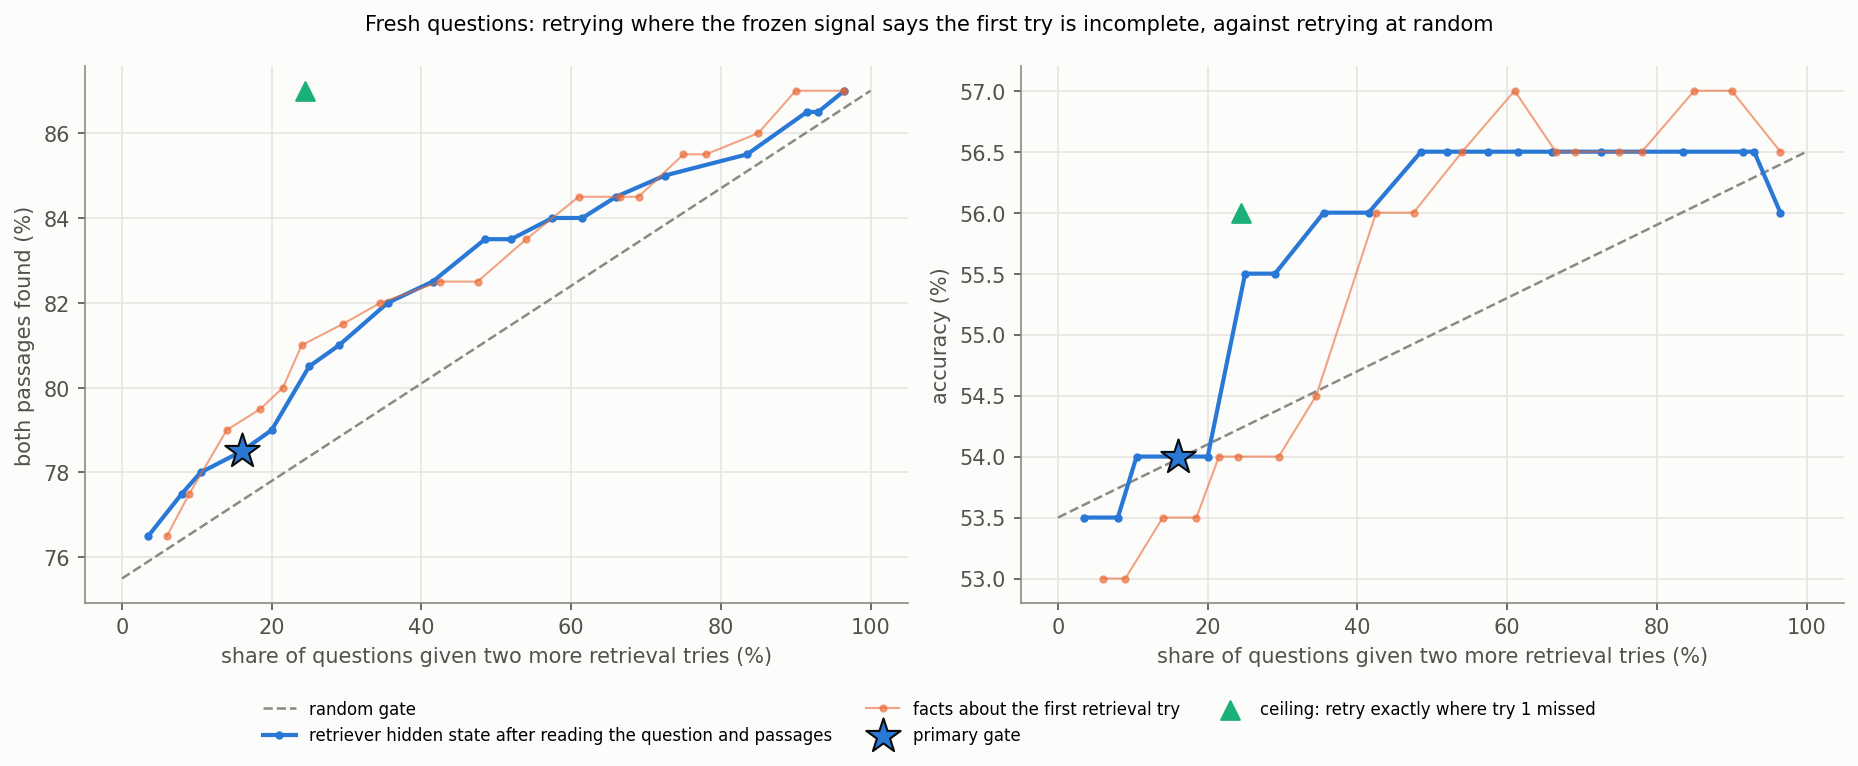

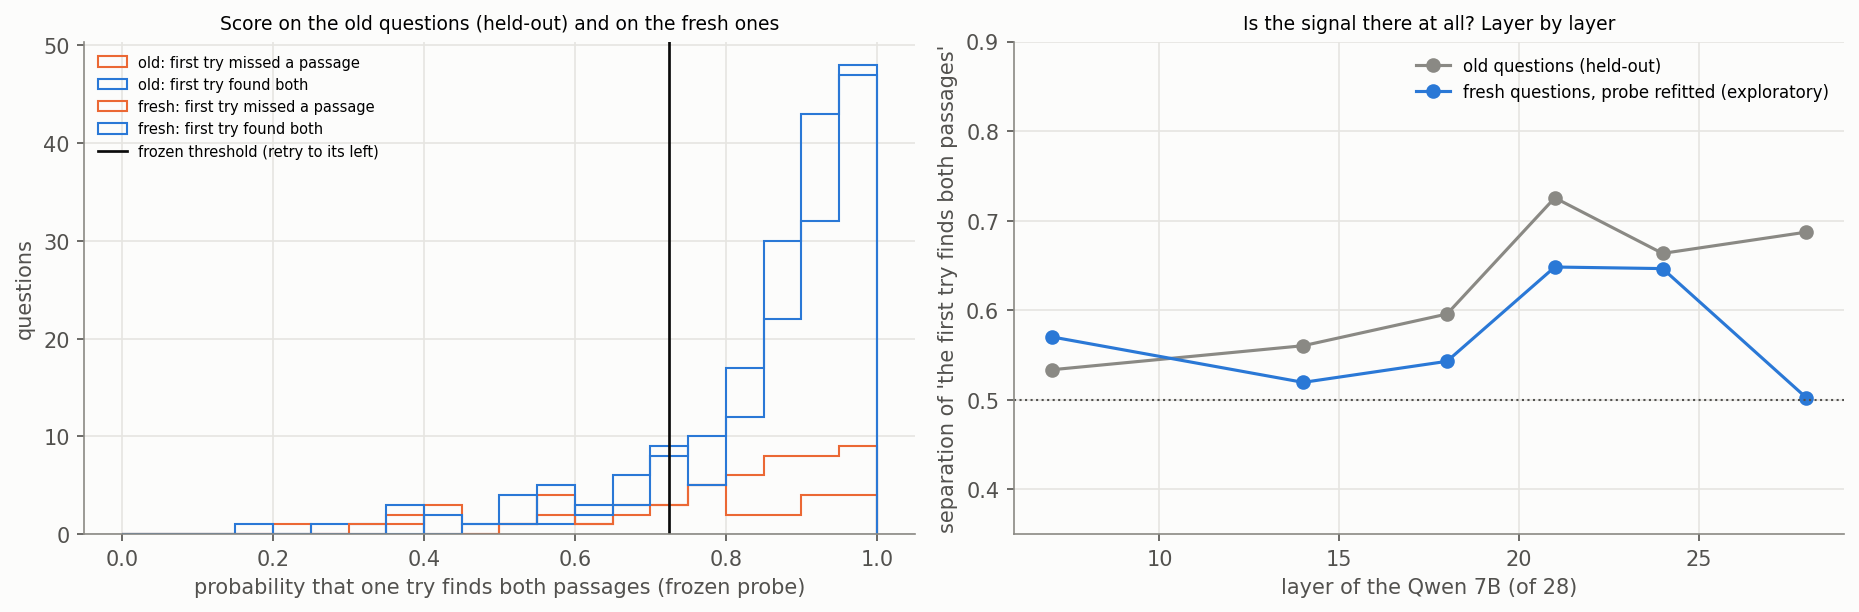

Wall-clock this session (s): {'copy_q7': 414, 'extract_retrieve_q7': 80, 'evaluate_retriever': 34, 'total_session': 579}
Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final/results_retriever/set5e_retriever_gate.xlsx

ALL DONE.
Saved to Drive.


In [6]:
USE_FROZEN = f"{RUN_DIR}/frozen_retriever"
if DRY_RUN:      # a throwaway gate for the fake model, made from the old questions
    sweeps = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{OLD_SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d and os.path.exists(f"{d}/results/per_question.jsonl")]
    OLD_SWEEP = sweeps[-1]
    OLD_DATA = json.load(open(f"{OLD_SWEEP}/config.json"))["data_dir"]
    DRY_OLD = f"{RUN_DIR}/dry_old"
    os.makedirs(f"{DRY_OLD}/step", exist_ok=True)
    run_stage("hidden.py", ["extract", "--model", "q7", "--role", "retrieve", "--sweep_run", OLD_SWEEP, "--data_dir", OLD_DATA, "--run_dir", DRY_OLD,
                            "--models_json", f"{RUN_DIR}/models.json", "--backend", "tiny"], "dry_extract_old_retrieve.log")
    USE_FROZEN = f"{RUN_DIR}/frozen_retriever_dry"
    run_stage("retriever_check.py", ["freeze", "--sweep_run", OLD_SWEEP, "--hidden_run", DRY_OLD, "--data_dir", OLD_DATA, "--models_json", f"{OLD_SWEEP}/models.json",
                                     "--gate_dir", GATE_DIR, "--out_dir", USE_FROZEN, "--repeats", 1], "dry_freeze_retriever.log")
run_stage("retriever_check.py", ["evaluate", "--frozen_dir", USE_FROZEN] + COMMON, "evaluate_retriever.log")
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RUN_DIR}/results_retriever/summary.md").read()))
for f in sorted(glob.glob(f"{RUN_DIR}/results_retriever/charts/*.png")):
    display(Image(f))
TIMES["total_session"] = round(time.time() - T_START)
ver = subprocess.run([sys.executable, "-c", "import torch, transformers; print('torch', torch.__version__, '| transformers', transformers.__version__)"],
                     capture_output=True, text=True).stdout.strip()
json.dump({"session": SESSION, "label": "retriever", "run_dir": RUN_DIR, "gpu": gpu, "seconds": TIMES, "versions": ver, "code": EXPECTED_CODE,
           "frozen_checksum": FROZEN["npz_sha256"]}, open(f"{SESSION_DIR}/session.json", "w"), indent=1)
print("Wall-clock this session (s):", TIMES)
print("Excel workbook:", f"{RUN_DIR}/results_retriever/set5e_retriever_gate.xlsx")
print("\nALL DONE.")
try:
    drive.flush_and_unmount()
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)